In [1]:
# ==============================================
# 1. 导入依赖库
# ==============================================
import os
import time
import random
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Dataset

# 设置中文显示
plt.rcParams["font.family"] = ["SimHei", "WenQuanYi Micro Hei", "Heiti TC", "Microsoft YaHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False

# ==============================================
# 1.1 固定随机种子（可复现）
# ==============================================
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

# ==============================================
# 1.2 指标函数（稳健）
# ==============================================
def safe_mape(y_true, y_pred, threshold=5.0):
    """仅在真实值>=threshold时计算MAPE，避免低流量爆炸"""
    mask = y_true >= threshold
    if np.sum(mask) == 0:
        return np.nan
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100

def smape(y_true, y_pred, eps=1e-6):
    return np.mean(2.0 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + eps)) * 100

def wape(y_true, y_pred, eps=1e-6):
    return np.sum(np.abs(y_true - y_pred)) / (np.sum(np.abs(y_true)) + eps) * 100

# ==============================================
# 1.3 自动寻找数据路径
# ==============================================
def auto_find_data_file(filename="pems04.npz"):
    # 常见路径
    candidates = [
        Path(filename),
        Path(".jupyter") / filename,
        Path("data") / filename,
        Path("dataset") / filename,
        Path("datasets") / filename
    ]
    for p in candidates:
        if p.exists():
            return p.resolve()

    # 递归搜索
    found = list(Path(".").rglob(filename))
    if found:
        return found[0].resolve()

    raise FileNotFoundError(f"未找到数据文件 {filename}，请确认已放入项目目录。")


# ==============================================
# 2. 自定义数据集类
# ==============================================
class TrafficDataset(Dataset):
    def __init__(self, data, time_step=12):
        self.data = data
        self.time_step = time_step

    def __len__(self):
        return len(self.data) - self.time_step

    def __getitem__(self, idx):
        x = self.data[idx:idx + self.time_step, :]
        y = self.data[idx + self.time_step, :]
        return torch.FloatTensor(x), torch.FloatTensor(y)

# ==============================================
# 3. 数据加载与预处理
# ==============================================
def load_pems_data(data_path, time_step=12, split_ratio=[0.7, 0.15]):
    if not os.path.exists(data_path):
        raise FileNotFoundError(f"数据集不存在：{data_path}")

    print(f"📥 加载数据集：{data_path}")
    data = np.load(data_path)['data']
    flow_data = data[:, :, 0]
    print(f"✅ 原始数据形状：{flow_data.shape}（时间步×路段数）")
    print(f"📊 原始数据范围：min={flow_data.min():.2f}, max={flow_data.max():.2f}")

    # 归一化
    scaler = MinMaxScaler(feature_range=(0.1, 0.9))
    scaled_data = scaler.fit_transform(flow_data)
    print(f"✅ 数据归一化完成，路段总数：{scaler.n_features_in_}")

    # 划分数据集
    total_samples = len(scaled_data) - time_step
    train_size = int(total_samples * split_ratio[0])
    val_size = int(total_samples * split_ratio[1])

    train_data = scaled_data[:train_size + time_step]
    val_data = scaled_data[train_size : train_size + val_size + time_step]
    test_data = scaled_data[train_size + val_size : ]

    train_dataset = TrafficDataset(train_data, time_step)
    val_dataset = TrafficDataset(val_data, time_step)
    test_dataset = TrafficDataset(test_data, time_step)

    print(f"\n📊 数据集划分：")
    print(f"  训练集：{len(train_dataset)}样本 | 验证集：{len(val_dataset)}样本 | 测试集：{len(test_dataset)}样本")
    return train_dataset, val_dataset, test_dataset, scaler, flow_data

# ==============================================
# 4. CNN-LSTM模型
# ==============================================
class CNN_LSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=64, num_layers=2, cnn_out_channels=16):
        super(CNN_LSTM, self).__init__()
        
        self.cnn = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=cnn_out_channels, kernel_size=(3, 3), padding=1),
            nn.ReLU(),
            nn.BatchNorm2d(cnn_out_channels),
            nn.Conv2d(in_channels=cnn_out_channels, out_channels=cnn_out_channels*2, kernel_size=(3, 3), padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=(2, 1), stride=(2, 1))
        )
        
        # 动态计算输出维度，避免手算错误
        with torch.no_grad():
            dummy = torch.randn(1, 1, 12, input_dim)
            out = self.cnn(dummy)
            _, c, t, s = out.shape
            self.cnn_output_dim = c * s
        
        self.lstm = nn.LSTM(
            input_size=self.cnn_output_dim,
            hidden_size=hidden_dim,
            num_layers=num_layers,
            batch_first=True,
            dropout=0.2
        )
        
        self.fc = nn.Sequential(
            nn.Linear(hidden_dim, input_dim),
            nn.ReLU()
        )

    def forward(self, x):
        x = x.unsqueeze(1)  # [B,1,T,S]
        cnn_out = self.cnn(x)
        b, c, t, s = cnn_out.shape
        lstm_in = cnn_out.permute(0, 2, 1, 3).reshape(b, t, -1)
        lstm_out, _ = self.lstm(lstm_in)
        out = self.fc(lstm_out[:, -1, :])
        return out

# ==============================================
# 5. 模型训练函数（增加早停+最佳模型）
# ==============================================
def train_model(model, train_loader, val_loader, epochs=60, lr=0.001, device="cpu", patience=10):
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', patience=5, factor=0.5, verbose=True)
    
    train_losses, val_losses = [], []
    model.to(device)
    start_time = time.time()

    best_val = float("inf")
    best_state = None
    early_stop_count = 0

    print(f"\n🚀 开始训练（最多{epochs}轮），设备：{device}")
    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        
        for batch_idx, (x, y) in enumerate(train_loader):
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            outputs = model(x)
            loss = criterion(outputs, y)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
            optimizer.step()
            train_loss += loss.item() * x.size(0)

        train_loss_avg = train_loss / len(train_loader.dataset)
        train_losses.append(train_loss_avg)

        # 验证
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for x, y in val_loader:
                x, y = x.to(device), y.to(device)
                outputs = model(x)
                loss = criterion(outputs, y)
                val_loss += loss.item() * x.size(0)

        val_loss_avg = val_loss / len(val_loader.dataset)
        val_losses.append(val_loss_avg)
        scheduler.step(val_loss_avg)

        # 最佳模型记录 + 早停
        if val_loss_avg < best_val:
            best_val = val_loss_avg
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
            early_stop_count = 0
        else:
            early_stop_count += 1

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(f"Epoch {epoch+1:03d}/{epochs} | Train: {train_loss_avg:.6f} | Val: {val_loss_avg:.6f} | LR: {optimizer.param_groups[0]['lr']:.6g}")

        if early_stop_count >= patience:
            print(f"⏹️ 早停触发：验证集连续{patience}轮无提升")
            break

    if best_state is not None:
        model.load_state_dict(best_state)

    total_time = time.time() - start_time
    print(f"✅ 训练完成！最佳验证损失：{best_val:.6f} | 总耗时: {total_time:.2f}秒（约{total_time/60:.1f}分钟）")
    return model, train_losses, val_losses

# ==============================================
# 6. 一次性评估（返回所有需要的数据）
# ==============================================
def evaluate_all(model, test_loader, scaler, device="cpu", mape_threshold=5.0):
    model.eval()
    y_true, y_pred = [], []
    
    with torch.no_grad():
        for x, y in test_loader:
            x = x.to(device)
            outputs = model(x).cpu().numpy()
            y_true.extend(y.numpy())
            y_pred.extend(outputs)

    y_true = scaler.inverse_transform(np.array(y_true))
    y_pred = scaler.inverse_transform(np.array(y_pred))
    y_pred = np.maximum(y_pred, 0)

    # 全局指标（全路段展平）
    yt = y_true.reshape(-1)
    yp = y_pred.reshape(-1)
    global_metrics = {
        "MAE": mean_absolute_error(yt, yp),
        "RMSE": mean_squared_error(yt, yp, squared=False),
        "R2": r2_score(yt, yp),
        "WAPE": wape(yt, yp),
        "sMAPE": smape(yt, yp),
        "MAPE_filtered": safe_mape(yt, yp, threshold=mape_threshold)
    }

    # 第1路段指标（保留你原有口径）
    seg0_metrics = {
        "mae": mean_absolute_error(y_true[:, 0], y_pred[:, 0]),
        "rmse": mean_squared_error(y_true[:, 0], y_pred[:, 0], squared=False),
        "mape": safe_mape(y_true[:, 0], y_pred[:, 0], threshold=mape_threshold),
        "r2": r2_score(y_true[:, 0], y_pred[:, 0])
    }

    # 每路段MAE
    all_mae = [mean_absolute_error(y_true[:, i], y_pred[:, i]) for i in range(y_true.shape[1])]

    return y_true, y_pred, seg0_metrics, global_metrics, all_mae

def visualize_basic_prediction(y_true, y_pred, segment_idx=0, steps=200):
    plt.figure(figsize=(12, 6))
    steps = min(steps, len(y_true))
    plt.plot(y_true[:steps, segment_idx], color="#1f77b4", label="真实流量")
    plt.plot(y_pred[:steps, segment_idx], color="#ff7f0e", linestyle="--", label="预测流量")
    plt.xlabel("时间步（5分钟/步）")
    plt.ylabel("车流量（辆）")
    plt.title(f"路段{segment_idx+1}预测结果对比（测试集）")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

def visualize_mae_distribution(all_mae):
    plt.figure(figsize=(12, 5))
    plt.hist(all_mae, bins=30, color="#1f77b4", alpha=0.75, edgecolor="white")
    plt.axvline(np.mean(all_mae), color="red", linestyle="--", linewidth=2, label=f"均值={np.mean(all_mae):.2f}")
    plt.axvline(np.median(all_mae), color="orange", linestyle="--", linewidth=2, label=f"中位数={np.median(all_mae):.2f}")
    plt.xlabel("MAE（辆）")
    plt.ylabel("路段数量")
    plt.title("各路段MAE分布")
    plt.legend()
    plt.grid(alpha=0.3, axis="y")
    plt.tight_layout()
    plt.show()

# ==============================================
# 7. 时段性能分析（改用稳健MAPE）
# ==============================================
def evaluate_time_periods_all_segments(y_true, y_pred, step_interval=5, mape_threshold=5.0):
    times = pd.date_range(start="00:00", periods=len(y_true), freq=f"{step_interval}min")
    hours = times.hour

    periods = {
        "深夜 (0:00-6:00)": (0, 6),
        "早高峰 (7:00-9:00)": (7, 9),
        "上午平峰 (9:00-12:00)": (9, 12),
        "午间 (12:00-14:00)": (12, 14),
        "下午平峰 (14:00-17:00)": (14, 17),
        "晚高峰 (17:00-19:00)": (17, 19),
        "夜间 (19:00-24:00)": (19, 24)
    }

    period_results = {}
    
    for period_name, (start_hour, end_hour) in periods.items():
        mask = (hours >= start_hour) & (hours < end_hour) if start_hour < end_hour else (hours >= start_hour) | (hours < end_hour)
        if np.sum(mask) == 0:
            continue

        period_true = y_true[mask]
        period_pred = y_pred[mask]

        t = period_true.reshape(-1)
        p = period_pred.reshape(-1)

        period_results[period_name] = {
            'mae': mean_absolute_error(t, p),
            'rmse': mean_squared_error(t, p, squared=False),
            'wape': wape(t, p),
            'smape': smape(t, p),
            'mape_filtered': safe_mape(t, p, threshold=mape_threshold),
            'sample_count': int(np.sum(mask))
        }

    return period_results

def visualize_period_performance(period_results):
    periods = list(period_results.keys())
    maes = [period_results[p]['mae'] for p in periods]
    wapes = [period_results[p]['wape'] for p in periods]
    
    fig, ax1 = plt.subplots(figsize=(14, 7))
    bars = ax1.bar(periods, maes, alpha=0.7, color='skyblue', label='MAE')
    ax1.set_ylabel('MAE (辆)', color='blue')
    ax1.tick_params(axis='y', labelcolor='blue')

    for b, v in zip(bars, maes):
        ax1.text(b.get_x() + b.get_width()/2., v + 0.2, f'{v:.1f}', ha='center')

    ax2 = ax1.twinx()
    ax2.plot(periods, wapes, 'ro-', linewidth=2, markersize=7, label='WAPE')
    ax2.set_ylabel('WAPE (%)', color='red')
    ax2.tick_params(axis='y', labelcolor='red')

    ax1.set_title('全路段不同时段预测性能对比（MAE + WAPE）')
    ax1.set_xlabel('时段')
    plt.xticks(rotation=30)
    ax1.grid(alpha=0.3)

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

    plt.tight_layout()
    plt.show()

def print_period_analysis(period_results):
    print("\n" + "="*60)
    print("📊 全路段时段性能分析报告")
    print("="*60)

    best_mae_period = min(period_results.items(), key=lambda x: x[1]['mae'])
    worst_mae_period = max(period_results.items(), key=lambda x: x[1]['mae'])

    print(f"\n🏆 性能最佳时段 (MAE): {best_mae_period[0]} | MAE={best_mae_period[1]['mae']:.2f}")
    print(f"⚠️  性能最差时段 (MAE): {worst_mae_period[0]} | MAE={worst_mae_period[1]['mae']:.2f}")

    print(f"\n📈 详细时段分析:")
    for period_name, m in period_results.items():
        print(f"  {period_name}: MAE={m['mae']:.2f}, RMSE={m['rmse']:.2f}, WAPE={m['wape']:.2f}%, sMAPE={m['smape']:.2f}%, 样本={m['sample_count']}")

    all_mae = [m['mae'] for m in period_results.values()]
    all_wape = [m['wape'] for m in period_results.values()]
    return {
        'best_period': best_mae_period[0],
        'worst_period': worst_mae_period[0],
        'overall_mae': float(np.mean(all_mae)),
        'overall_wape': float(np.mean(all_wape))
    }

# ==============================================
# 8. 预测函数
# ==============================================
def predict_realtime_all_segments(new_data, model_path, scaler_path, device="cpu"):
    scaler = joblib.load(scaler_path)
    input_dim = scaler.n_features_in_
    model = CNN_LSTM(input_dim=input_dim)

    model.load_state_dict(torch.load(model_path, map_location=device))
    model.to(device).eval()

    new_data_scaled = scaler.transform(new_data)
    with torch.no_grad():
        x = torch.FloatTensor(new_data_scaled).unsqueeze(0).to(device)
        pred_scaled = model(x).cpu().numpy()[0]

    pred_flow_all = scaler.inverse_transform([pred_scaled])[0]
    pred_flow_all = np.maximum(pred_flow_all, 0)
    return pred_flow_all

def display_all_segments_prediction(pred_flow_all, top_n=20):
    print(f"\n{'='*60}")
    print(f"🚗 下一时间步全路段流量预测结果")
    print(f"{'='*60}")
    print(f"总路段数: {len(pred_flow_all)}")

    pred_df = pd.DataFrame({
        '路段编号': range(1, len(pred_flow_all) + 1),
        '预测流量(辆)': pred_flow_all
    })

    print(f"\n📊 预测统计:")
    print(f"  • 平均流量: {np.mean(pred_flow_all):.2f} 辆")
    print(f"  • 最大流量: {np.max(pred_flow_all):.2f} 辆 (路段{np.argmax(pred_flow_all)+1})")
    print(f"  • 最小流量: {np.min(pred_flow_all):.2f} 辆 (路段{np.argmin(pred_flow_all)+1})")
    print(f"  • 流量标准差: {np.std(pred_flow_all):.2f} 辆")

    print(f"\n🏆 流量最高前{top_n}个路段:")
    for _, row in pred_df.nlargest(top_n, '预测流量(辆)').iterrows():
        print(f"  路段{int(row['路段编号']):3d}: {row['预测流量(辆)']:8.2f} 辆")

    print(f"\n📉 流量最低前{top_n}个路段:")
    for _, row in pred_df.nsmallest(top_n, '预测流量(辆)').iterrows():
        print(f"  路段{int(row['路段编号']):3d}: {row['预测流量(辆)']:8.2f} 辆")

    return pred_df

def visualize_all_segments_prediction(pred_flow_all, num_segments_to_plot=50):
    plt.figure(figsize=(15, 10))

    plt.subplot(2, 2, 1)
    plt.hist(pred_flow_all, bins=30, alpha=0.75, color='skyblue', edgecolor='black')
    plt.xlabel('预测流量 (辆)')
    plt.ylabel('路段数量')
    plt.title('全路段预测流量分布')
    plt.grid(alpha=0.3)

    plt.subplot(2, 2, 2)
    indices = np.arange(min(num_segments_to_plot, len(pred_flow_all)))
    plt.bar(indices, pred_flow_all[:num_segments_to_plot], alpha=0.75, color='lightcoral')
    plt.xlabel('路段编号')
    plt.ylabel('预测流量 (辆)')
    plt.title(f'前{num_segments_to_plot}个路段预测流量')
    plt.xticks(indices, [f'{i+1}' for i in indices], rotation=45)
    plt.grid(alpha=0.3)

    plt.subplot(2, 2, 3)
    sorted_flow = np.sort(pred_flow_all)[::-1]
    plt.plot(sorted_flow, 'g-', alpha=0.8)
    plt.xlabel('路段排名')
    plt.ylabel('预测流量 (辆)')
    plt.title('路段流量排名（从高到低）')
    plt.grid(alpha=0.3)

    plt.subplot(2, 2, 4)
    plt.boxplot(pred_flow_all, vert=True, patch_artist=True,
                boxprops=dict(facecolor='lightgreen', alpha=0.7))
    plt.ylabel('预测流量 (辆)')
    plt.title('全路段流量箱线图')
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

def save_prediction_to_csv(pred_flow_all, filename="next_step_prediction_all_segments.csv"):
    pred_df = pd.DataFrame({
        'segment_id': range(1, len(pred_flow_all) + 1),
        'predicted_flow': pred_flow_all
    })
    pred_df.to_csv(filename, index=False, encoding="utf-8-sig")
    print(f"\n💾 全路段预测结果已保存至: {filename}")
    return pred_df

# ==============================================
# 9. 保存函数（统一输出目录）
# ==============================================
def save_model(model, scaler, out_dir="outputs", model_name="traffic_model.pth", scaler_name="traffic_scaler.pkl"):
    Path(out_dir).mkdir(exist_ok=True)
    model_path = str(Path(out_dir) / model_name)
    scaler_path = str(Path(out_dir) / scaler_name)

    torch.save(model.state_dict(), model_path)
    joblib.dump(scaler, scaler_path)
    print(f"\n💾 模型保存至：{model_path}")
    print(f"💾 归一化器保存至：{scaler_path}")
    return model_path, scaler_path

# ==============================================
# 10. 总结报告
# ==============================================
def generate_final_summary(seg0_metrics, global_metrics, all_segments_mae, period_analysis, pred_flow_all):
    print("\n" + "="*80)
    print("🎯 CNN-LSTM交通流量预测模型 - 最终分析报告")
    print("="*80)

    print("\n📊 单路段(路段1)性能:")
    print(f"  MAE={seg0_metrics['mae']:.2f} | RMSE={seg0_metrics['rmse']:.2f} | MAPE(过滤)={seg0_metrics['mape']:.2f}% | R²={seg0_metrics['r2']:.4f}")

    print("\n📊 全局性能（全路段展平）:")
    print(f"  MAE={global_metrics['MAE']:.2f} | RMSE={global_metrics['RMSE']:.2f} | R²={global_metrics['R2']:.4f}")
    print(f"  WAPE={global_metrics['WAPE']:.2f}% | sMAPE={global_metrics['sMAPE']:.2f}% | MAPE(过滤)={global_metrics['MAPE_filtered']:.2f}%")

    print("\n📊 全路段统计:")
    print(f"  平均MAE={np.mean(all_segments_mae):.2f} | 中位数MAE={np.median(all_segments_mae):.2f}")
    print(f"  最优MAE={np.min(all_segments_mae):.2f}（路段{np.argmin(all_segments_mae)+1}）")
    print(f"  最差MAE={np.max(all_segments_mae):.2f}（路段{np.argmax(all_segments_mae)+1}）")

    print("\n⏰ 时段结论:")
    print(f"  最佳时段: {period_analysis['best_period']}")
    print(f"  最差时段: {period_analysis['worst_period']}")
    print(f"  平均MAE: {period_analysis['overall_mae']:.2f} | 平均WAPE: {period_analysis['overall_wape']:.2f}%")

    print("\n🔮 下一时间步全路段预测摘要:")
    print(f"  平均流量: {np.mean(pred_flow_all):.2f}")
    print(f"  最大流量: {np.max(pred_flow_all):.2f}（路段{np.argmax(pred_flow_all)+1}）")
    print(f"  最小流量: {np.min(pred_flow_all):.2f}（路段{np.argmin(pred_flow_all)+1}）")
    print("="*80)

# ==============================================
# 11. 主函数（完整流程）
# ==============================================
if __name__ == "__main__":
    # 配置参数
    data_path = str(auto_find_data_file("pems04.npz"))
    time_step = 12
    batch_size = 32
    hidden_dim = 64
    num_layers = 2
    epochs = 60
    lr = 0.001
    device = "cuda" if torch.cuda.is_available() else "cpu"

    try:
        print("🚀 开始CNN-LSTM交通流量预测完整流程")
        print("="*60)

        # 1. 加载数据
        train_dataset, val_dataset, test_dataset, scaler, flow_data = load_pems_data(data_path, time_step)
        input_dim = flow_data.shape[1]

        # 2. DataLoader
        train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
        val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
        test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

        # 3. 初始化模型
        model = CNN_LSTM(input_dim=input_dim, hidden_dim=hidden_dim, num_layers=num_layers)
        print(f"📌 模型参数量: {sum(p.numel() for p in model.parameters()):,}")

        # 4. 训练
        model, train_losses, val_losses = train_model(
            model, train_loader, val_loader, epochs=epochs, lr=lr, device=device, patience=10
        )

        # 可视化训练曲线
        plt.figure(figsize=(10, 5))
        plt.plot(train_losses, label="训练损失")
        plt.plot(val_losses, label="验证损失", linestyle="--")
        plt.xlabel("Epoch")
        plt.ylabel("Loss")
        plt.title("训练/验证损失曲线")
        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

        # 5. 一次性评估（替代原先两次）
        y_true, y_pred, seg0_metrics, global_metrics, all_segments_mae = evaluate_all(
            model, test_loader, scaler, device=device, mape_threshold=5.0
        )

        print("\n===== 基础评估（第1路段） =====")
        print(f"MAE: {seg0_metrics['mae']:.2f} | RMSE: {seg0_metrics['rmse']:.2f} | MAPE(过滤): {seg0_metrics['mape']:.2f}% | R²: {seg0_metrics['r2']:.4f}")

        print("\n===== 全局评估（全路段） =====")
        print(f"MAE: {global_metrics['MAE']:.2f} | RMSE: {global_metrics['RMSE']:.2f} | R²: {global_metrics['R2']:.4f}")
        print(f"WAPE: {global_metrics['WAPE']:.2f}% | sMAPE: {global_metrics['sMAPE']:.2f}% | MAPE(过滤): {global_metrics['MAPE_filtered']:.2f}%")

        print("\n===== 全路段MAE统计 =====")
        print(f"平均MAE: {np.mean(all_segments_mae):.2f} | 中位数MAE: {np.median(all_segments_mae):.2f}")
        print(f"最优路段: {np.min(all_segments_mae):.2f}（路段{np.argmin(all_segments_mae)+1}）")
        print(f"最差路段: {np.max(all_segments_mae):.2f}（路段{np.argmax(all_segments_mae)+1}）")

        visualize_basic_prediction(y_true, y_pred, segment_idx=0, steps=200)
        visualize_mae_distribution(all_segments_mae)

        # 6. 时段分析
        period_results = evaluate_time_periods_all_segments(y_true, y_pred, step_interval=5, mape_threshold=5.0)
        visualize_period_performance(period_results)
        period_analysis = print_period_analysis(period_results)

        # 7. 保存模型
        model_path, scaler_path = save_model(model, scaler, out_dir="outputs")

        # 8. 实时预测（用最后time_step个原始点）
        print("\n开始全路段下一时间步预测...")
        sample_data = flow_data[-time_step:, :]
        pred_flow_all = predict_realtime_all_segments(sample_data, model_path, scaler_path, device=device)

        display_all_segments_prediction(pred_flow_all, top_n=15)
        visualize_all_segments_prediction(pred_flow_all, num_segments_to_plot=50)
        save_prediction_to_csv(pred_flow_all, filename="outputs/next_step_prediction_all_segments.csv")

        # 9. 保存关键数值结果
        pd.DataFrame([global_metrics]).to_csv("outputs/global_metrics.csv", index=False, encoding="utf-8-sig")
        pd.DataFrame({"segment_id": np.arange(1, len(all_segments_mae)+1), "mae": all_segments_mae}).to_csv(
            "outputs/segment_mae.csv", index=False, encoding="utf-8-sig"
        )
        pd.DataFrame(period_results).T.to_csv("outputs/period_metrics.csv", encoding="utf-8-sig")

        # 10. 最终报告
        generate_final_summary(seg0_metrics, global_metrics, all_segments_mae, period_analysis, pred_flow_all)

    except Exception as e:
        print(f"\n❌ 运行出错：{str(e)}")
        import traceback
        traceback.print_exc()


🚀 开始CNN-LSTM交通流量预测完整流程
📥 加载数据集：C:\Users\Lenovo\.jupyter\pems04.npz
✅ 原始数据形状：(16992, 307)（时间步×路段数）
📊 原始数据范围：min=0.00, max=919.00
✅ 数据归一化完成，路段总数：307

📊 数据集划分：
  训练集：11886样本 | 验证集：2547样本 | 测试集：2547样本
📌 模型参数量: 2,589,907

🚀 开始训练（最多60轮），设备：cpu
Epoch 001/60 | Train: 0.027325 | Val: 0.014654 | LR: 0.001
Epoch 005/60 | Train: 0.003546 | Val: 0.003783 | LR: 0.001
Epoch 010/60 | Train: 0.003090 | Val: 0.003643 | LR: 0.001
Epoch 015/60 | Train: 0.002970 | Val: 0.003530 | LR: 0.001
Epoch 020/60 | Train: 0.002857 | Val: 0.003558 | LR: 0.001
Epoch 025/60 | Train: 0.002307 | Val: 0.002912 | LR: 0.001
Epoch 00029: reducing learning rate of group 0 to 5.0000e-04.
Epoch 030/60 | Train: 0.002164 | Val: 0.002795 | LR: 0.0005
Epoch 035/60 | Train: 0.002143 | Val: 0.002749 | LR: 0.0005
Epoch 040/60 | Train: 0.002122 | Val: 0.002734 | LR: 0.0005
Epoch 045/60 | Train: 0.002110 | Val: 0.002799 | LR: 0.0005
Epoch 00049: reducing learning rate of group 0 to 2.5000e-04.
Epoch 050/60 | Train: 0.002030 | Val: 0.0027

<Figure size 1000x500 with 1 Axes>


===== 基础评估（第1路段） =====
MAE: 28.35 | RMSE: 39.49 | MAPE(过滤): 12.42% | R²: 0.9180

===== 全局评估（全路段） =====
MAE: 23.57 | RMSE: 38.43 | R²: 0.9430
WAPE: 10.61% | sMAPE: 16.22% | MAPE(过滤): 14.31%

===== 全路段MAE统计 =====
平均MAE: 23.57 | 中位数MAE: 20.61
最优路段: 5.32（路段182）
最差路段: 153.46（路段138）


<Figure size 1200x600 with 1 Axes>

<Figure size 1200x500 with 1 Axes>

<Figure size 1400x700 with 2 Axes>


📊 全路段时段性能分析报告

🏆 性能最佳时段 (MAE): 夜间 (19:00-24:00) | MAE=11.22
⚠️  性能最差时段 (MAE): 午间 (12:00-14:00) | MAE=31.84

📈 详细时段分析:
  深夜 (0:00-6:00): MAE=22.79, RMSE=37.91, WAPE=10.46%, sMAPE=16.86%, 样本=648
  早高峰 (7:00-9:00): MAE=28.60, RMSE=43.66, WAPE=9.86%, sMAPE=10.83%, 样本=216
  上午平峰 (9:00-12:00): MAE=31.25, RMSE=48.54, WAPE=9.76%, sMAPE=10.98%, 样本=324
  午间 (12:00-14:00): MAE=31.84, RMSE=48.13, WAPE=9.47%, sMAPE=10.59%, 样本=216
  下午平峰 (14:00-17:00): MAE=27.40, RMSE=41.42, WAPE=10.29%, sMAPE=11.62%, 样本=324
  晚高峰 (17:00-19:00): MAE=21.64, RMSE=32.30, WAPE=12.84%, sMAPE=16.11%, 样本=216
  夜间 (19:00-24:00): MAE=11.22, RMSE=18.80, WAPE=17.37%, sMAPE=27.93%, 样本=495

💾 模型保存至：outputs\traffic_model.pth
💾 归一化器保存至：outputs\traffic_scaler.pkl

开始全路段下一时间步预测...

🚗 下一时间步全路段流量预测结果
总路段数: 307

📊 预测统计:
  • 平均流量: 65.91 辆
  • 最大流量: 320.61 辆 (路段98)
  • 最小流量: 0.00 辆 (路段75)
  • 流量标准差: 48.21 辆

🏆 流量最高前15个路段:
  路段 98:   320.61 辆
  路段204:   304.55 辆
  路段112:   223.78 辆
  路段 58:   215.43 辆
  路段 42:   209.82 辆
  路段 83:   200.9

<Figure size 1500x1000 with 4 Axes>


💾 全路段预测结果已保存至: outputs/next_step_prediction_all_segments.csv

🎯 CNN-LSTM交通流量预测模型 - 最终分析报告

📊 单路段(路段1)性能:
  MAE=28.35 | RMSE=39.49 | MAPE(过滤)=12.42% | R²=0.9180

📊 全局性能（全路段展平）:
  MAE=23.57 | RMSE=38.43 | R²=0.9430
  WAPE=10.61% | sMAPE=16.22% | MAPE(过滤)=14.31%

📊 全路段统计:
  平均MAE=23.57 | 中位数MAE=20.61
  最优MAE=5.32（路段182）
  最差MAE=153.46（路段138）

⏰ 时段结论:
  最佳时段: 夜间 (19:00-24:00)
  最差时段: 午间 (12:00-14:00)
  平均MAE: 24.96 | 平均WAPE: 11.44%

🔮 下一时间步全路段预测摘要:
  平均流量: 65.91
  最大流量: 320.61（路段98）
  最小流量: 0.00（路段75）


已找到CSV目录: C:\Users\Lenovo\outputs


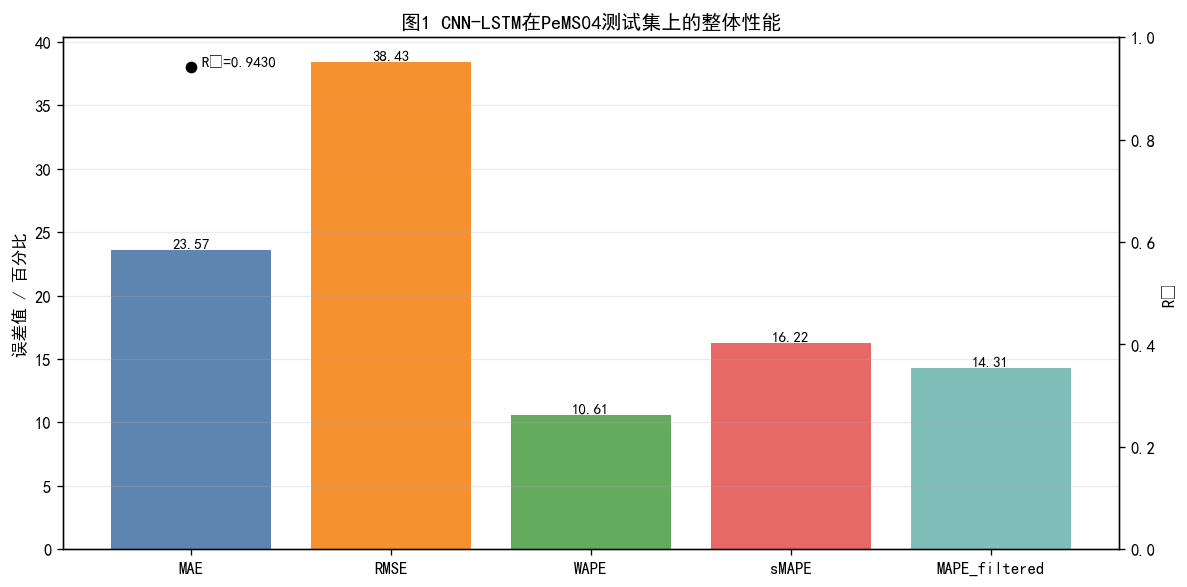

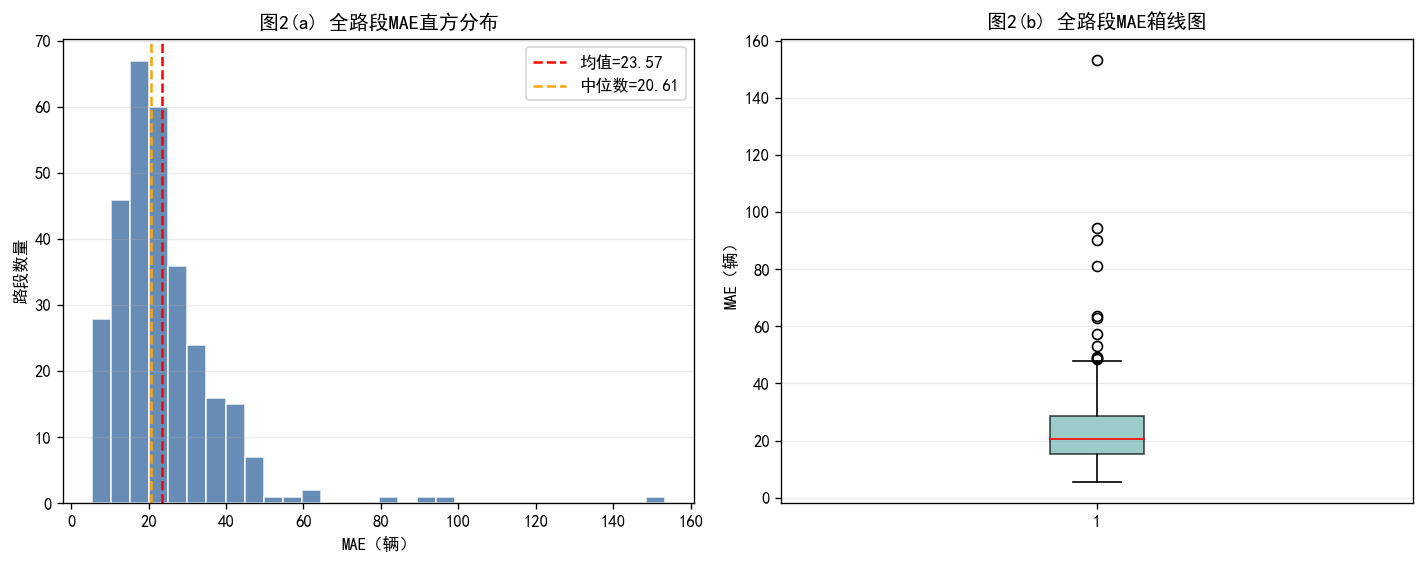

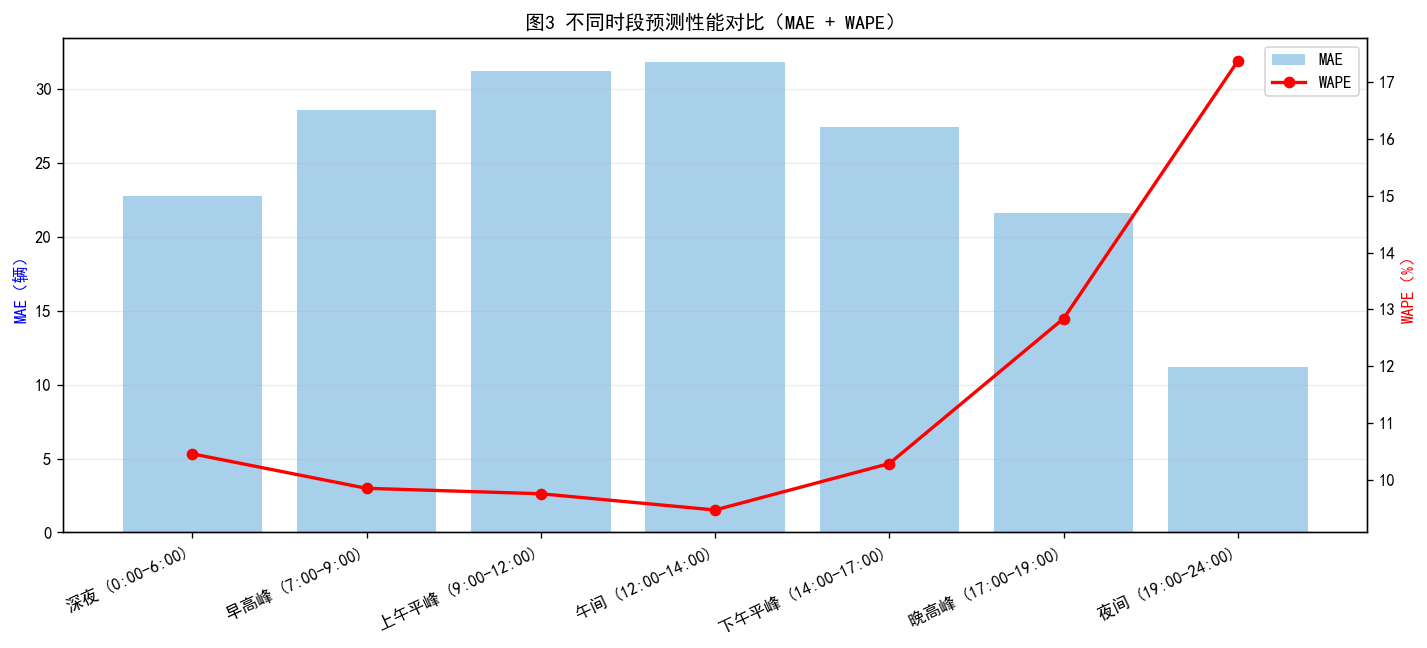

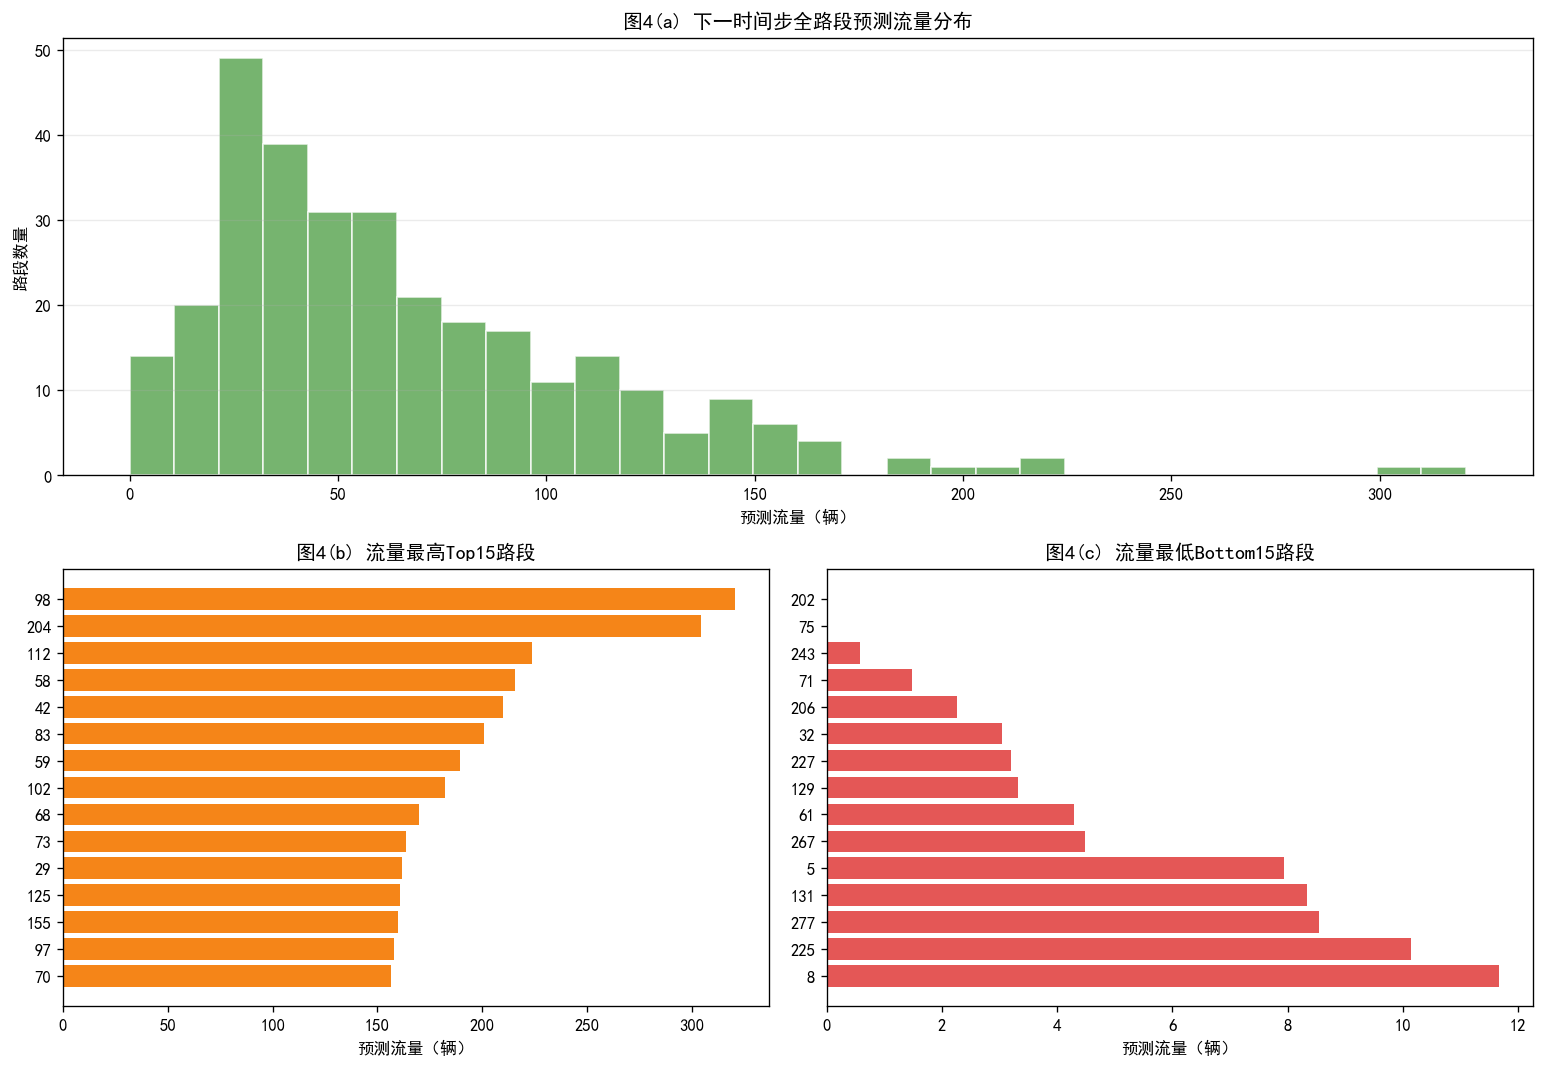


图表与表格已生成：
- C:\Users\Lenovo\outputs\figures\fig1_global_metrics.png
- C:\Users\Lenovo\outputs\figures\fig2_segment_mae_distribution.png
- C:\Users\Lenovo\outputs\figures\fig3_period_performance.png
- C:\Users\Lenovo\outputs\figures\fig4_next_step_prediction.png
- C:\Users\Lenovo\outputs\figures\table1_core_metrics.csv


In [4]:
# ================================
# Notebook版（自动搜索CSV目录）
# 功能：自动在常见目录和当前目录下递归查找4个CSV，
#      然后生成论文图表到 outputs/figures/
# ================================

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------
# 0) 画图风格
# -----------------------------
plt.rcParams["font.family"] = ["SimHei", "Microsoft YaHei", "WenQuanYi Micro Hei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

# -----------------------------
# 1) 自动定位CSV目录
# -----------------------------
required = [
    "global_metrics.csv",
    "segment_mae.csv",
    "period_metrics.csv",
    "next_step_prediction_all_segments.csv",
]

# 你可在这里加/改常见根目录
search_roots = [
    Path.cwd(),
    Path("/home/anan/代码数据"),
    Path("/home/anan"),
    Path.home(),
]

def find_dirs_with_file(filename, roots):
    results = []
    for root in roots:
        if root.exists():
            results.extend(list(root.rglob(filename)))
    return results

# 先根据 global_metrics.csv 找候选目录，再校验4个文件是否都在
global_candidates = find_dirs_with_file("global_metrics.csv", search_roots)
valid_dirs = []

for fp in global_candidates:
    d = fp.parent
    if all((d / f).exists() for f in required):
        valid_dirs.append(d)

# 去重
valid_dirs = list(dict.fromkeys(valid_dirs))

if not valid_dirs:
    raise FileNotFoundError(
        "未找到包含4个CSV的目录。\n"
        "请确认已生成并保存以下文件：\n"
        "- global_metrics.csv\n"
        "- segment_mae.csv\n"
        "- period_metrics.csv\n"
        "- next_step_prediction_all_segments.csv"
    )

# 选文件数量最多/路径最短的第一个（通常最合理）
csv_dir = valid_dirs[0]
print("已找到CSV目录:", csv_dir)

OUT_DIR = csv_dir
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# -----------------------------
# 2) 读取CSV
# -----------------------------
global_metrics = pd.read_csv(OUT_DIR / "global_metrics.csv").iloc[0].to_dict()
segment_mae = pd.read_csv(OUT_DIR / "segment_mae.csv")
period_metrics = pd.read_csv(OUT_DIR / "period_metrics.csv", index_col=0)
pred_next = pd.read_csv(OUT_DIR / "next_step_prediction_all_segments.csv")

# 单路段指标（若你有最新值可改）
seg0_metrics = {
    "mae": 28.35,
    "rmse": 39.49,
    "mape": 12.42,
    "r2": 0.9180,
}

# -----------------------------
# 图1：整体性能指标
# -----------------------------
fig, ax1 = plt.subplots(figsize=(10, 5))

metric_names = ["MAE", "RMSE", "WAPE", "sMAPE", "MAPE_filtered"]
metric_vals = [float(global_metrics[k]) for k in metric_names]

bars = ax1.bar(
    metric_names,
    metric_vals,
    color=["#4C78A8", "#F58518", "#54A24B", "#E45756", "#72B7B2"],
    alpha=0.9
)
ax1.set_ylabel("误差值 / 百分比")
ax1.set_title("图1 CNN-LSTM在PeMS04测试集上的整体性能")
ax1.grid(axis="y", alpha=0.25)

for b, v in zip(bars, metric_vals):
    ax1.text(b.get_x() + b.get_width() / 2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)

# R²点标注
ax2 = ax1.twinx()
ax2.plot([0], [float(global_metrics["R2"])], "o", color="black")
ax2.set_ylim(0, 1.0)
ax2.set_ylabel("R²", color="black")
ax2.text(0.05, float(global_metrics["R2"]), f"R²={float(global_metrics['R2']):.4f}",
         ha="left", va="bottom", fontsize=9)

plt.tight_layout()
fig1_path = FIG_DIR / "fig1_global_metrics.png"
plt.savefig(fig1_path, bbox_inches="tight")
plt.show()
plt.close()

# -----------------------------
# 图2：路段MAE分布
# -----------------------------
mae_vals = segment_mae["mae"].astype(float).values
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

axes[0].hist(mae_vals, bins=30, color="#4C78A8", alpha=0.85, edgecolor="white")
axes[0].axvline(mae_vals.mean(), color="red", linestyle="--", label=f"均值={mae_vals.mean():.2f}")
axes[0].axvline(np.median(mae_vals), color="orange", linestyle="--", label=f"中位数={np.median(mae_vals):.2f}")
axes[0].set_xlabel("MAE（辆）")
axes[0].set_ylabel("路段数量")
axes[0].set_title("图2(a) 全路段MAE直方分布")
axes[0].legend()
axes[0].grid(alpha=0.25, axis="y")

axes[1].boxplot(
    mae_vals,
    vert=True,
    patch_artist=True,
    boxprops=dict(facecolor="#72B7B2", alpha=0.7),
    medianprops=dict(color="red"),
)
axes[1].set_ylabel("MAE（辆）")
axes[1].set_title("图2(b) 全路段MAE箱线图")
axes[1].grid(alpha=0.25, axis="y")

plt.tight_layout()
fig2_path = FIG_DIR / "fig2_segment_mae_distribution.png"
plt.savefig(fig2_path, bbox_inches="tight")
plt.show()
plt.close()

# -----------------------------
# 图3：分时段性能（MAE + WAPE）
# -----------------------------
period_order = [
    "深夜 (0:00-6:00)",
    "早高峰 (7:00-9:00)",
    "上午平峰 (9:00-12:00)",
    "午间 (12:00-14:00)",
    "下午平峰 (14:00-17:00)",
    "晚高峰 (17:00-19:00)",
    "夜间 (19:00-24:00)",
]

period_df = period_metrics.loc[[p for p in period_order if p in period_metrics.index]]

fig, ax1 = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(period_df))
mae = period_df["mae"].astype(float).values
wape = period_df["wape"].astype(float).values

ax1.bar(x, mae, color="#A0CBE8", alpha=0.9, label="MAE")
ax1.set_xticks(x)
ax1.set_xticklabels(period_df.index, rotation=25, ha="right")
ax1.set_ylabel("MAE（辆）", color="blue")
ax1.set_title("图3 不同时段预测性能对比（MAE + WAPE）")
ax1.grid(alpha=0.25, axis="y")

ax2 = ax1.twinx()
ax2.plot(x, wape, color="red", marker="o", linewidth=2, label="WAPE")
ax2.set_ylabel("WAPE（%）", color="red")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

plt.tight_layout()
fig3_path = FIG_DIR / "fig3_period_performance.png"
plt.savefig(fig3_path, bbox_inches="tight")
plt.show()
plt.close()

# -----------------------------
# 图4：下一时间步预测分布 + Top/Bottom15
# -----------------------------
pred = pred_next["predicted_flow"].astype(float).values
pred_sorted_desc = pred_next.sort_values("predicted_flow", ascending=False).head(15)
pred_sorted_asc = pred_next.sort_values("predicted_flow", ascending=True).head(15)

fig = plt.figure(figsize=(13, 9))

ax1 = plt.subplot(2, 1, 1)
ax1.hist(pred, bins=30, color="#54A24B", alpha=0.8, edgecolor="white")
ax1.set_title("图4(a) 下一时间步全路段预测流量分布")
ax1.set_xlabel("预测流量（辆）")
ax1.set_ylabel("路段数量")
ax1.grid(alpha=0.25, axis="y")

ax2 = plt.subplot(2, 2, 3)
ax2.barh(
    pred_sorted_desc["segment_id"].astype(int).astype(str),
    pred_sorted_desc["predicted_flow"].astype(float),
    color="#F58518"
)
ax2.invert_yaxis()
ax2.set_title("图4(b) 流量最高Top15路段")
ax2.set_xlabel("预测流量（辆）")

ax3 = plt.subplot(2, 2, 4)
ax3.barh(
    pred_sorted_asc["segment_id"].astype(int).astype(str),
    pred_sorted_asc["predicted_flow"].astype(float),
    color="#E45756"
)
ax3.invert_yaxis()
ax3.set_title("图4(c) 流量最低Bottom15路段")
ax3.set_xlabel("预测流量（辆）")

plt.tight_layout()
fig4_path = FIG_DIR / "fig4_next_step_prediction.png"
plt.savefig(fig4_path, bbox_inches="tight")
plt.show()
plt.close()

# -----------------------------
# 表1：核心指标汇总
# -----------------------------
summary_rows = [
    ["单路段(路段1)", "MAE", seg0_metrics["mae"]],
    ["单路段(路段1)", "RMSE", seg0_metrics["rmse"]],
    ["单路段(路段1)", "MAPE(过滤)%", seg0_metrics["mape"]],
    ["单路段(路段1)", "R²", seg0_metrics["r2"]],
    ["全局(全路段展平)", "MAE", float(global_metrics["MAE"])],
    ["全局(全路段展平)", "RMSE", float(global_metrics["RMSE"])],
    ["全局(全路段展平)", "R²", float(global_metrics["R2"])],
    ["全局(全路段展平)", "WAPE(%)", float(global_metrics["WAPE"])],
    ["全局(全路段展平)", "sMAPE(%)", float(global_metrics["sMAPE"])],
    ["全局(全路段展平)", "MAPE(过滤)%", float(global_metrics["MAPE_filtered"])],
]
summary_df = pd.DataFrame(summary_rows, columns=["评估范围", "指标", "数值"])
table_path = FIG_DIR / "table1_core_metrics.csv"
summary_df.to_csv(table_path, index=False, encoding="utf-8-sig")

print("\n图表与表格已生成：")
print(f"- {fig1_path}")
print(f"- {fig2_path}")
print(f"- {fig3_path}")
print(f"- {fig4_path}")
print(f"- {table_path}")


In [5]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ================================
# 1) 基础配置
# ================================
plt.rcParams["font.family"] = ["SimHei", "Microsoft YaHei", "WenQuanYi Micro Hei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300

required_files = [
    "global_metrics.csv",
    "segment_mae.csv",
    "period_metrics.csv",
    "next_step_prediction_all_segments.csv",
]

# 可按需增加搜索根目录
search_roots = [
    Path.cwd(),
    Path("/home/anan/代码数据"),
    Path("/home/anan"),
    Path.home(),
]

# ================================
# 2) 自动搜索包含全部CSV的目录
# ================================
def find_candidate_dirs(roots, target="global_metrics.csv"):
    candidates = []
    for root in roots:
        if root.exists():
            for p in root.rglob(target):
                candidates.append(p.parent)
    return candidates

candidate_dirs = find_candidate_dirs(search_roots)
valid_dirs = []

for d in candidate_dirs:
    if all((d / f).exists() for f in required_files):
        valid_dirs.append(d.resolve())

# 去重
valid_dirs = list(dict.fromkeys(valid_dirs))

if not valid_dirs:
    raise FileNotFoundError(
        "未找到包含4个CSV的目录，请确认已生成：\n"
        "- global_metrics.csv\n"
        "- segment_mae.csv\n"
        "- period_metrics.csv\n"
        "- next_step_prediction_all_segments.csv"
    )

# 默认使用第一个匹配目录（通常就是最新实验目录）
OUT_DIR = valid_dirs[0]
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("已找到CSV目录：", OUT_DIR)
print("图表输出目录：", FIG_DIR)

# ================================
# 3) 读取CSV
# ================================
global_metrics = pd.read_csv(OUT_DIR / "global_metrics.csv").iloc[0].to_dict()
segment_mae = pd.read_csv(OUT_DIR / "segment_mae.csv")
period_metrics = pd.read_csv(OUT_DIR / "period_metrics.csv", index_col=0)
pred_next = pd.read_csv(OUT_DIR / "next_step_prediction_all_segments.csv")

# 若你有最新的路段1指标可改这里
seg0_metrics = {
    "mae": 28.35,
    "rmse": 39.49,
    "mape": 12.42,
    "r2": 0.9180
}

# ================================
# 图1：整体性能指标
# ================================
fig, ax1 = plt.subplots(figsize=(10, 5))
metric_names = ["MAE", "RMSE", "WAPE", "sMAPE", "MAPE_filtered"]
metric_vals = [float(global_metrics[k]) for k in metric_names]

bars = ax1.bar(metric_names, metric_vals,
               color=["#4C78A8", "#F58518", "#54A24B", "#E45756", "#72B7B2"], alpha=0.9)
ax1.set_ylabel("误差值 / 百分比")
ax1.set_title("图1 CNN-LSTM在PeMS04测试集上的整体性能")
ax1.grid(axis="y", alpha=0.25)

for b, v in zip(bars, metric_vals):
    ax1.text(b.get_x() + b.get_width()/2, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)

ax2 = ax1.twinx()
ax2.plot([0], [float(global_metrics["R2"])], "o", color="black")
ax2.set_ylim(0, 1.0)
ax2.set_ylabel("R²", color="black")
ax2.text(0.05, float(global_metrics["R2"]),
         f"R²={float(global_metrics['R2']):.4f}", ha="left", va="bottom", fontsize=9)

plt.tight_layout()
fig1_path = FIG_DIR / "fig1_global_metrics.png"
plt.savefig(fig1_path, bbox_inches="tight")
plt.show()
plt.close()

# ================================
# 图2：路段MAE分布（直方图+箱线图）
# ================================
mae_vals = segment_mae["mae"].astype(float).values
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

axes[0].hist(mae_vals, bins=30, color="#4C78A8", alpha=0.85, edgecolor="white")
axes[0].axvline(mae_vals.mean(), color="red", linestyle="--", label=f"均值={mae_vals.mean():.2f}")
axes[0].axvline(np.median(mae_vals), color="orange", linestyle="--", label=f"中位数={np.median(mae_vals):.2f}")
axes[0].set_xlabel("MAE（辆）")
axes[0].set_ylabel("路段数量")
axes[0].set_title("图2(a) 全路段MAE直方分布")
axes[0].legend()
axes[0].grid(alpha=0.25, axis="y")

axes[1].boxplot(mae_vals, vert=True, patch_artist=True,
                boxprops=dict(facecolor="#72B7B2", alpha=0.7),
                medianprops=dict(color="red"))
axes[1].set_ylabel("MAE（辆）")
axes[1].set_title("图2(b) 全路段MAE箱线图")
axes[1].grid(alpha=0.25, axis="y")

plt.tight_layout()
fig2_path = FIG_DIR / "fig2_segment_mae_distribution.png"
plt.savefig(fig2_path, bbox_inches="tight")
plt.show()
plt.close()

# ================================
# 图3：分时段性能（MAE柱 + WAPE线）
# ================================
period_order = [
    "深夜 (0:00-6:00)",
    "早高峰 (7:00-9:00)",
    "上午平峰 (9:00-12:00)",
    "午间 (12:00-14:00)",
    "下午平峰 (14:00-17:00)",
    "晚高峰 (17:00-19:00)",
    "夜间 (19:00-24:00)"
]

period_df = period_metrics.loc[[p for p in period_order if p in period_metrics.index]]

fig, ax1 = plt.subplots(figsize=(12, 5.5))
x = np.arange(len(period_df))
mae = period_df["mae"].astype(float).values
wape = period_df["wape"].astype(float).values

ax1.bar(x, mae, color="#A0CBE8", alpha=0.9, label="MAE")
ax1.set_xticks(x)
ax1.set_xticklabels(period_df.index, rotation=25, ha="right")
ax1.set_ylabel("MAE（辆）", color="blue")
ax1.set_title("图3 不同时段预测性能对比（MAE + WAPE）")
ax1.grid(alpha=0.25, axis="y")

ax2 = ax1.twinx()
ax2.plot(x, wape, color="red", marker="o", linewidth=2, label="WAPE")
ax2.set_ylabel("WAPE（%）", color="red")

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

plt.tight_layout()
fig3_path = FIG_DIR / "fig3_period_performance.png"
plt.savefig(fig3_path, bbox_inches="tight")
plt.show()
plt.close()

# ================================
# 图4：下一时间步预测（分布 + Top/Bottom15）
# ================================
pred = pred_next["predicted_flow"].astype(float).values
top15 = pred_next.sort_values("predicted_flow", ascending=False).head(15)
bottom15 = pred_next.sort_values("predicted_flow", ascending=True).head(15)

fig = plt.figure(figsize=(13, 9))

ax1 = plt.subplot(2, 1, 1)
ax1.hist(pred, bins=30, color="#54A24B", alpha=0.8, edgecolor="white")
ax1.set_title("图4(a) 下一时间步全路段预测流量分布")
ax1.set_xlabel("预测流量（辆）")
ax1.set_ylabel("路段数量")
ax1.grid(alpha=0.25, axis="y")

ax2 = plt.subplot(2, 2, 3)
ax2.barh(top15["segment_id"].astype(int).astype(str),
         top15["predicted_flow"].astype(float),
         color="#F58518")
ax2.invert_yaxis()
ax2.set_title("图4(b) 流量最高Top15路段")
ax2.set_xlabel("预测流量（辆）")

ax3 = plt.subplot(2, 2, 4)
ax3.barh(bottom15["segment_id"].astype(int).astype(str),
         bottom15["predicted_flow"].astype(float),
         color="#E45756")
ax3.invert_yaxis()
ax3.set_title("图4(c) 流量最低Bottom15路段")
ax3.set_xlabel("预测流量（辆）")

plt.tight_layout()
fig4_path = FIG_DIR / "fig4_next_step_prediction.png"
plt.savefig(fig4_path, bbox_inches="tight")
plt.show()
plt.close()

# ================================
# 表1：核心指标汇总
# ================================
summary_rows = [
    ["单路段(路段1)", "MAE", seg0_metrics["mae"]],
    ["单路段(路段1)", "RMSE", seg0_metrics["rmse"]],
    ["单路段(路段1)", "MAPE(过滤)%", seg0_metrics["mape"]],
    ["单路段(路段1)", "R²", seg0_metrics["r2"]],
    ["全局(全路段展平)", "MAE", float(global_metrics["MAE"])],
    ["全局(全路段展平)", "RMSE", float(global_metrics["RMSE"])],
    ["全局(全路段展平)", "R²", float(global_metrics["R2"])],
    ["全局(全路段展平)", "WAPE(%)", float(global_metrics["WAPE"])],
    ["全局(全路段展平)", "sMAPE(%)", float(global_metrics["sMAPE"])],
    ["全局(全路段展平)", "MAPE(过滤)%", float(global_metrics["MAPE_filtered"])],
]
summary_df = pd.DataFrame(summary_rows, columns=["评估范围", "指标", "数值"])
table_path = FIG_DIR / "table1_core_metrics.csv"
summary_df.to_csv(table_path, index=False, encoding="utf-8-sig")

print("\n图表与表格已生成：")
print(f"- {fig1_path}")
print(f"- {fig2_path}")
print(f"- {fig3_path}")
print(f"- {fig4_path}")
print(f"- {table_path}")
|

SyntaxError: invalid syntax (<ipython-input-5-59f80f8212e1>, line 245)